# Week 7 — Seoul Bike Sharing: AI-Enhanced Digital Twin (Team B) — enhanced version

**Goal:** Extend the Week 5 calibrated model and the Week 6 data-integration workflow with machine learning, and test whether AI improves predictions on **unseen, later** observations.

| Task | Model | Equation |
|---|---|---|
| **B1** | Direct AI demand model (Random Forest) | `D_AI(t) = f_AI(weather(t), calendar(t))` |
| **B2** | One-hour-ahead AI forecast (Random Forest) | `D_forecast(t+1) = g_AI(D(t), D(t−1), X(t))` |
| **B3** | Hybrid model: Week 5 baseline + AI residual correction | `D_hybrid(t) = D_base(t) + r_AI(t)` |

**Test period:** 15–28 October 2018 (the same period as the Week 6 context-based estimate), so all methods can be compared directly. All models are trained **only on earlier hours**. There is no random shuffling.

**Data sources:**
- `SeoulBikeData.csv` — historical hourly rentals + weather/calendar (ground truth for rentals).
- **Open-Meteo Historical API** (Week 6 integration) — hourly `cloud_cover` for Seoul, requested in `Asia/Seoul` local time. A downloaded CSV is only an explicit, logged fallback.
- **Open-Meteo Forecast API** — only in the separate Section 11 (future scenario 26–30 Nov 2026).

**What each model is allowed to see (historical test):**

| Model | Past rentals | Weather | Calendar of target hour |
|---|---|---|---|
| Week 6 rule-based | historical reference hours only | target-hour temperature (matching) | ✓ |
| Week 5 linear | `D(t)` | target-hour `T(t+1)`, `H(t+1)` (perfect-forecast assumption from Week 5) | hour |
| B1 direct AI | ✗ none | target-hour weather + cloud cover (perfect-forecast assumption) | ✓ |
| B2 forecast AI | `D(t)`, `D(t−1)` | **current** weather + cloud cover `X(t)` only — no future weather | ✓ |
| B3 hybrid | `D(t)`, `D(t−1)` | target-hour weather + cloud cover (perfect-forecast assumption) | ✓ |

The calendar of the next hour (hour of day, weekday, holiday) is known in advance, so it is a valid input. Observed rentals of the target hour are **never** used as inputs.

### Change log (relative to the original `week7_seoul_ai_hybrid.ipynb`)

| Status | Item |
|---|---|
| **Kept** | Data cleaning, lag construction, chronological split, `week5_matrix()`, `rule_based()` (`MIN_MATCHES=1`, ±1 h, ±3 °C), `RF_PARAMS`, `BASE_FIT_SHARE=0.7`, B1/B2/B3 Random Forest methods, all original plots. |
| **Modified** | B1/B3 get `Cloud_next`, B2 gets `Cloud_now` (switch: `USE_CLOUD_FEATURE`). B3 plot/table now compare the **hybrid with its own part-A baseline** (`Hybrid baseline only` vs `B3 hybrid`); `Week 5 linear` stays as a separate benchmark. Comparison table has coverage and includes `Hybrid baseline only`. The static results text was replaced by numbers computed from this run. |
| **New** | Section 2b: Open-Meteo Historical API integration (API-first, validated, provenance printed, CSV fallback only explicit). Cloud-feature ablation (with vs. without cloud). B3 error breakdown by day type / peak hours. Section 11: future scenario 26–30 Nov 2026 from the Open-Meteo Forecast API (no ground truth, no metrics). Exports in `outputs/`. |

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.ensemble import RandomForestRegressor

TEST_START = pd.Timestamp('2018-10-15 00:00')
TEST_END = pd.Timestamp('2018-10-28 23:00')

# Week 6 rule-based settings (same values as the original Week 6 notebook)
HOUR_TOLERANCE = 1
TEMPERATURE_TOLERANCE = 3.0
MIN_MATCHES = 1

# Random Forest settings (fixed before looking at the test period)
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)

# B3: share of the training period used to fit the baseline (rest: residual model)
BASE_FIT_SHARE = 0.7

#  Week 6 external data integration (Open-Meteo)
LAT, LON = 37.57, 126.96
SEOUL_TZ = 'Asia/Seoul'
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
FORECAST_URL = 'https://api.open-meteo.com/v1/forecast'
CLOUD_CSV = 'open-meteo-37.57N126.96E27m.csv'  # offline fallback only; its timestamps are GMT/UTC
ALLOW_CSV_FALLBACK = True    # False -> stop (fail fast) if the Historical API is not available
USE_CLOUD_FEATURE = True     # add cloud cover to B1/B2/B3; Section 9 also reports the models without it

OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Load and prepare the Seoul observations

Same checks as in Weeks 5–6: timestamps from `Date` + `Hour` (Seoul local time), missing values, duplicates and invalid values. Calendar context is derived from the timestamp and the existing `Holiday` column.

In [21]:
csv_path = next(p for p in [Path('../SeoulBikeData.csv'), Path('SeoulBikeData.csv')] if p.exists())
df = pd.read_csv(csv_path, encoding='latin1')
df['Timestamp'] = pd.to_datetime(df['Date'], dayfirst=True) + pd.to_timedelta(df['Hour'], unit='h')

print('Rows:', len(df))
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate timestamps:', int(df['Timestamp'].duplicated().sum()))

df = df.dropna().drop_duplicates('Timestamp').sort_values('Timestamp').reset_index(drop=True)
df = df[(df['Rented Bike Count'] >= 0) & df['Humidity(%)'].between(0, 100)].copy()

df['Operating'] = df['Functioning Day'].eq('Yes')
df['Weekday'] = df['Timestamp'].dt.day_of_week            # 0 = Monday ... 6 = Sunday
df['Day type'] = np.where(df['Weekday'] >= 5, 'weekend', 'weekday')
df['Is weekend'] = (df['Weekday'] >= 5).astype(int)
df['Is holiday'] = df['Holiday'].eq('Holiday').astype(int)
df['Month'] = df['Timestamp'].dt.month

print('Clean rows:', len(df), '| Period:', df.Timestamp.min(), 'to', df.Timestamp.max())

Rows: 8760
Missing values: 0
Duplicate timestamps: 0
Clean rows: 8760 | Period: 2017-12-01 00:00:00 to 2018-11-30 23:00:00


## 2b. Week 6 integration — Open-Meteo historical cloud cover (API first)

The Seoul Bike CSV stays the source of truth for rentals and its own weather. Hourly **cloud cover** (`cloud_cover_pct`, %) is added from the **Open-Meteo Historical API** (ERA5 reanalysis, the same source as Week 6) for Seoul (37.57 N, 126.96 E).

- The API is requested with `timezone=Asia/Seoul`, so its times are already Seoul local hours — **no extra +9 h** is added. The response's `utc_offset_seconds` is checked.
- Only if the API fails **and** `ALLOW_CSV_FALLBACK=True`, the downloaded CSV is used; its GMT timestamps are converted UTC → `Asia/Seoul`. The fallback is printed, never silent.
- Checks: duplicated hours, non-numeric/missing values, 0–100 % range, complete coverage of all bike hours, one-to-one merge on the same local timestamp, and an hour-alignment check against the dataset's own solar radiation.
- Cloud cover is reanalysis data, not an issued forecast — for the historical test it is used with the same perfect-forecast assumption as the other target-hour weather.

In [3]:
def find_file(name):
    for p in [Path(name), Path('..') / name, Path('../Week-6') / name]:
        if p.exists():
            return p
    raise FileNotFoundError(f'{name} not found (needed only as API fallback)')

def cloud_from_api(start, end):
    params = {'latitude': LAT, 'longitude': LON, 'start_date': start, 'end_date': end,
              'hourly': 'cloud_cover', 'timezone': SEOUL_TZ, 'models': 'era5'}
    response = requests.get(ARCHIVE_URL, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()
    if payload.get('utc_offset_seconds') != 9 * 3600:
        raise ValueError(f"Unexpected API time zone: {payload.get('timezone')}")
    hourly = payload['hourly']
    if len(hourly['time']) != len(hourly['cloud_cover']):
        raise ValueError('API time and cloud_cover arrays differ in length')
    cloud = pd.DataFrame({'Timestamp': pd.to_datetime(hourly['time']),  # already Seoul local time
                          'cloud_cover_pct': pd.to_numeric(pd.Series(hourly['cloud_cover']), errors='coerce')})
    return cloud, payload

def cloud_from_csv():
    raw = pd.read_csv(find_file(CLOUD_CSV), skiprows=2)
    if not {'time', 'cloud_cover (%)'} <= set(raw.columns):
        raise ValueError('Unexpected cloud-cover CSV headers')
    return pd.DataFrame({
        'Timestamp': pd.to_datetime(raw['time'], utc=True).dt.tz_convert(SEOUL_TZ).dt.tz_localize(None),
        'cloud_cover_pct': pd.to_numeric(raw['cloud_cover (%)'], errors='coerce')})

start, end = df['Timestamp'].min().strftime('%Y-%m-%d'), df['Timestamp'].max().strftime('%Y-%m-%d')
try:
    cloud, payload = cloud_from_api(start, end)
    CLOUD_SOURCE = 'API: Open-Meteo Historical (ERA5), timezone=Asia/Seoul'
    (OUTPUT_DIR / 'open_meteo_historical_raw.json').write_text(json.dumps(payload), encoding='utf-8')
except (requests.RequestException, KeyError, ValueError) as exc:
    if not ALLOW_CSV_FALLBACK:
        raise
    print('WARNING: Historical API failed -> using the CSV FALLBACK. Reason:', repr(exc))
    cloud = cloud_from_csv()
    CLOUD_SOURCE = f'CSV fallback: {CLOUD_CSV} (GMT converted to Asia/Seoul)'

cloud = cloud.sort_values('Timestamp').reset_index(drop=True)
quality = {
    'cloud_source': CLOUD_SOURCE,
    'cloud_rows': len(cloud),
    'cloud_duplicate_hours': int(cloud['Timestamp'].duplicated().sum()),
    'cloud_missing_or_non_numeric': int(cloud['cloud_cover_pct'].isna().sum()),
    'cloud_outside_0_100': int((~cloud['cloud_cover_pct'].dropna().between(0, 100)).sum()),
}
assert quality['cloud_duplicate_hours'] == 0, 'Duplicated cloud-cover hours'
assert quality['cloud_outside_0_100'] == 0, 'Cloud cover outside 0–100 %'

# Processed copy: the raw bike columns are not overwritten, cloud is added as a new column
rows_before = len(df)
df = df.merge(cloud, on='Timestamp', how='left', validate='one_to_one')
assert len(df) == rows_before, 'Merge changed the number of bike hours'
quality['bike_hours'] = rows_before
quality['bike_hours_without_cloud'] = int(df['cloud_cover_pct'].isna().sum())

# Hour-alignment check: after removing the daily cycle, cloud cover should be most negatively
# correlated with the dataset's own solar radiation at lag 0. Another best lag = shifted hours.
solar = df['Solar Radiation (MJ/m2)']
solar_anomaly = solar - solar.groupby(df['Hour']).transform('mean')
lag_corr = {lag: round(solar_anomaly.corr(df['cloud_cover_pct'].shift(lag)), 3) for lag in range(-3, 4)}
quality['alignment_best_lag_h'] = min(lag_corr, key=lag_corr.get)
quality['alignment_corr_by_lag'] = lag_corr
if quality['alignment_best_lag_h'] != 0:
    print('WARNING: cloud cover seems shifted by', quality['alignment_best_lag_h'], 'h – check the time zone!')

(OUTPUT_DIR / 'quality_report.json').write_text(json.dumps(quality, indent=2, ensure_ascii=False), encoding='utf-8')
print('>>> CLOUD DATA SOURCE:', CLOUD_SOURCE)
print(json.dumps(quality, indent=2, ensure_ascii=False))

>>> CLOUD DATA SOURCE: API: Open-Meteo Historical (ERA5), timezone=Asia/Seoul
{
  "cloud_source": "API: Open-Meteo Historical (ERA5), timezone=Asia/Seoul",
  "cloud_rows": 8760,
  "cloud_duplicate_hours": 0,
  "cloud_missing_or_non_numeric": 0,
  "cloud_outside_0_100": 0,
  "bike_hours": 8760,
  "bike_hours_without_cloud": 0,
  "alignment_best_lag_h": 0,
  "alignment_corr_by_lag": {
    "-3": -0.211,
    "-2": -0.225,
    "-1": -0.237,
    "0": -0.243,
    "1": -0.239,
    "2": -0.228,
    "3": -0.21
  }
}


## 3. Build one dataset row per target hour

Each row describes a **target hour** (the hour we want to predict) together with information that is available one hour earlier:

- `D_t`, `D_t1`: observed rentals in the previous hour and two hours before.
- `T_now`, `H_now`, `Rain_now`, `Wind_now`: weather observed in the previous hour (known at forecast time).
- `T_next`, `H_next`, `Rain_next`, `Wind_next`: weather of the target hour (used only by models with the perfect-forecast assumption).

Rows are kept only if the three hours are consecutive and the service was operating in all of them (a zero during a shutdown is not zero demand).
- `Cloud_now` = cloud cover of the previous hour (known at forecast time), `Cloud_next` = cloud cover of the target hour (perfect-forecast assumption, like `T_next`).

Rows without cloud cover are dropped (the count is printed).

In [4]:
prev1 = df.shift(1)
prev2 = df.shift(2)

data = pd.DataFrame({
    'Timestamp': df['Timestamp'],
    'Hour': df['Hour'],
    'Weekday': df['Weekday'],
    'Is weekend': df['Is weekend'],
    'Is holiday': df['Is holiday'],
    'Month': df['Month'],
    'Seasons': df['Seasons'],
    'Day type': df['Day type'],
    'D_t': prev1['Rented Bike Count'],
    'D_t1': prev2['Rented Bike Count'],
    'T_now': prev1['Temperature(°C)'],
    'H_now': prev1['Humidity(%)'],
    'Rain_now': prev1['Rainfall(mm)'],
    'Wind_now': prev1['Wind speed (m/s)'],
    'T_next': df['Temperature(°C)'],
    'H_next': df['Humidity(%)'],
    'Rain_next': df['Rainfall(mm)'],
    'Wind_next': df['Wind speed (m/s)'],
    'Cloud_now': prev1['cloud_cover_pct'],
    'Cloud_next': df['cloud_cover_pct'],
    'Observed': df['Rented Bike Count'].astype(float),
})

consecutive = (df['Timestamp'] - prev1['Timestamp'] == pd.Timedelta(hours=1)) & \
              (prev1['Timestamp'] - prev2['Timestamp'] == pd.Timedelta(hours=1))
operating = df['Operating'] & prev1['Operating'].eq(True) & prev2['Operating'].eq(True)
data = data[consecutive & operating]
print('Valid target hours dropped because cloud cover is missing:',
      int(data[['Cloud_now', 'Cloud_next']].isna().any(axis=1).sum()))
data = data.dropna().reset_index(drop=True)

train = data[data['Timestamp'] < TEST_START].copy()
test = data[data['Timestamp'].between(TEST_START, TEST_END)].copy()
assert train['Timestamp'].max() < test['Timestamp'].min()

print('Training hours:', len(train), '|', train.Timestamp.min(), '->', train.Timestamp.max())
print('Test hours:    ', len(test), '|', test.Timestamp.min(), '->', test.Timestamp.max())

Valid target hours dropped because cloud cover is missing: 0
Training hours: 7389 | 2017-12-01 02:00:00 -> 2018-10-14 23:00:00
Test hours:     336 | 2018-10-15 00:00:00 -> 2018-10-28 23:00:00


## 4. Metrics and helper functions

- **MAE**: average absolute error (bicycles/hour).
- **RMSE**: like MAE, but large errors count more (bicycles/hour).
- **R²**: share of the variation explained (1 = perfect, 0 = no better than the test mean).

Predictions are clipped at zero only for reporting, because rentals cannot be negative.

In [5]:
def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def r2(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))

def scores(y, p):
    return {'MAE': mae(y, p), 'RMSE': rmse(y, p), 'R²': r2(y, p)}

def plot_test(columns, title):
    # One continuous hourly index so missing hours appear as gaps, not lines
    chart = test.set_index('Timestamp')[['Observed'] + columns].asfreq('h')
    plt.figure(figsize=(13, 5))
    plt.plot(chart.index, chart['Observed'], label='Observed', color='black', linewidth=2)
    for column in columns:
        plt.plot(chart.index, chart[column], label=column, alpha=0.85)
    plt.title(title)
    plt.xlabel('Time (Seoul)')
    plt.ylabel('Bicycle rentals / hour')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

## 5. Baselines from earlier weeks

### 5.1 Week 5 calibrated linear model

`D(t+1) = b0 + b1·D(t) + b2·T(t+1) + b3·H(t+1) + g(hour)`, calibrated by least squares on the training hours only (same equation as Week 5, refitted on all hours before the test period, as in Week 6).

In [6]:
def week5_matrix(d):
    return np.column_stack(
        [np.ones(len(d)), d['D_t'], d['T_next'], d['H_next']]
        + [(d['Hour'] == h).astype(float) for h in range(1, 24)]
    )

b_week5, *_ = np.linalg.lstsq(week5_matrix(train), train['Observed'], rcond=None)
test['Week 5 linear'] = np.maximum(0, week5_matrix(test) @ b_week5)

print('Week 5 coefficients b0–b3:', np.round(b_week5[:4], 3))
print('Week 5 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['Week 5 linear']).items()})

Week 5 coefficients b0–b3: [-23.448   0.87    4.178  -1.114]
Week 5 test scores: {'MAE': 147.44, 'RMSE': 217.42, 'R²': 0.87}


### 5.2 Week 6 context-based (rule-based) estimate

Same transparent rules as Week 6: for each test hour, take all **earlier** operating hours with the same season, the same day type (weekday/weekend), the same holiday status, an hour of day within ±1 hour and a temperature within ±3 °C. The estimate is the **median** of their rentals. No past rentals of the test day are used. Hours without any match stay empty (`NaN`) — they are not filled.

In [7]:
history = df[df['Operating'] & (df['Timestamp'] < TEST_START)]

def rule_based(target):
    hour_diff = (history['Hour'] - target['Hour']).abs()
    hour_diff = np.minimum(hour_diff, 24 - hour_diff)
    matches = history[
        (history['Seasons'] == target['Seasons'])
        & (history['Day type'] == target['Day type'])
        & (history['Is holiday'] == target['Is holiday'])
        & (hour_diff <= HOUR_TOLERANCE)
        & ((history['Temperature(°C)'] - target['T_next']).abs() <= TEMPERATURE_TOLERANCE)
    ]
    return matches['Rented Bike Count'].median() if len(matches) >= MIN_MATCHES else np.nan

test['Rule-based (Week 6)'] = test.apply(rule_based, axis=1)
covered = test['Rule-based (Week 6)'].notna()
print(f'Rule-based coverage: {covered.sum()} / {len(test)} test hours')
print('Rule-based scores (covered hours):',
      {k: round(v, 2) for k, v in scores(test.loc[covered, 'Observed'], test.loc[covered, 'Rule-based (Week 6)']).items()})

Rule-based coverage: 312 / 336 test hours
Rule-based scores (covered hours): {'MAE': 186.21, 'RMSE': 304.37, 'R²': 0.75}


## 6. B1 — Learn demand patterns (direct AI)

A Random Forest learns rentals directly from **weather and calendar** variables of the target hour. It receives **no past rentals**, so it describes typical demand under given conditions (like the Week 6 rules, but learned from data).

**Features:**

| Feature | Meaning | Unit |
|---|---|---|
| `Hour` | hour of day | 0–23 |
| `Weekday` | day of week | 0 = Monday … 6 = Sunday |
| `Is weekend` | Saturday or Sunday | 0/1 |
| `Is holiday` | public holiday | 0/1 |
| `Month` | calendar month (season) | 1–12 |
| `T_next` | temperature | °C |
| `H_next` | relative humidity | % |
| `Rain_next` | rainfall | mm |
| `Wind_next` | wind speed | m/s |
| `Cloud_next` | cloud cover (Open-Meteo) | % |

Weather of the target hour is treated as a perfect forecast, the same assumption as the Week 5 model.

B1 features: ['Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month', 'T_next', 'H_next', 'Rain_next', 'Wind_next', 'Cloud_next']
B1 test scores: {'MAE': 134.72, 'RMSE': 208.61, 'R²': 0.88}
Week 5 test scores: {'MAE': 147.44, 'RMSE': 217.42, 'R²': 0.87}


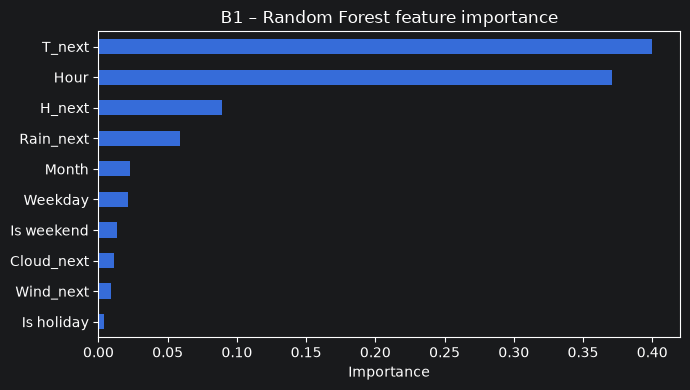

In [8]:
B1_FEATURES_ORIGINAL = ['Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month',
                        'T_next', 'H_next', 'Rain_next', 'Wind_next']
B1_FEATURES = B1_FEATURES_ORIGINAL + (['Cloud_next'] if USE_CLOUD_FEATURE else [])
assert 'Observed' not in B1_FEATURES

model_b1 = RandomForestRegressor(**RF_PARAMS).fit(train[B1_FEATURES], train['Observed'])
test['B1 direct AI'] = np.maximum(0, model_b1.predict(test[B1_FEATURES]))

print('B1 features:', B1_FEATURES)
print('B1 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['B1 direct AI']).items()})
print('Week 5 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['Week 5 linear']).items()})

importance = pd.Series(model_b1.feature_importances_, index=B1_FEATURES).sort_values()
importance.plot(kind='barh', figsize=(7, 4), title='B1 – Random Forest feature importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

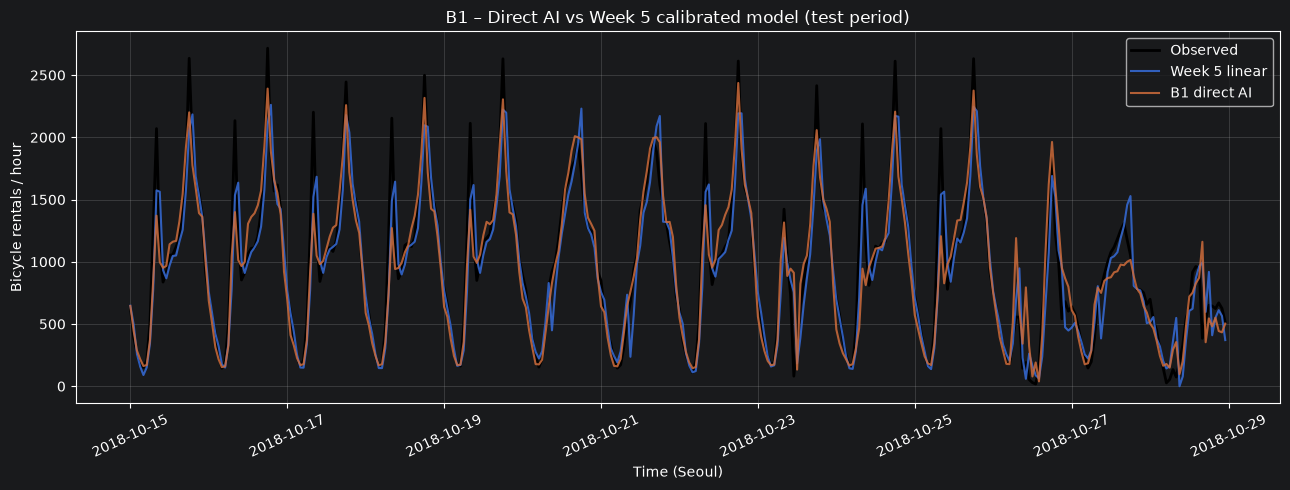

In [9]:
plot_test(['Week 5 linear', 'B1 direct AI'], 'B1 – Direct AI vs Week 5 calibrated model (test period)')

## 7. B2 — One-hour-ahead forecast

`D_forecast(t+1) = g_AI(D(t), D(t−1), X(t))`

At forecast time `t` we know the current and previous rentals, the **current** weather and the calendar of the next hour. Future observed weather and rentals are **not** used. This is a stricter (more realistic) setting than the Week 5 model, which used the observed weather of `t+1`.

`Cloud_now` (cloud cover of the current hour `t`) is added; the target-hour cloud cover `Cloud_next` is **not** allowed.

In [10]:
B2_FEATURES_ORIGINAL = ['D_t', 'D_t1', 'T_now', 'H_now', 'Rain_now', 'Wind_now',
                        'Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month']
B2_FEATURES = B2_FEATURES_ORIGINAL + (['Cloud_now'] if USE_CLOUD_FEATURE else [])

# Safety check: no target-hour weather or target rentals in the inputs
assert not set(B2_FEATURES) & {'Observed', 'T_next', 'H_next', 'Rain_next', 'Wind_next', 'Cloud_next'}

model_b2 = RandomForestRegressor(**RF_PARAMS).fit(train[B2_FEATURES], train['Observed'])
test['B2 forecast AI'] = np.maximum(0, model_b2.predict(test[B2_FEATURES]))

print('B2 features:', B2_FEATURES)
print('B2 test scores:', {k: round(v, 2) for k, v in scores(test['Observed'], test['B2 forecast AI']).items()})
print('Rule-based (covered hours):',
      {k: round(v, 2) for k, v in scores(test.loc[covered, 'Observed'], test.loc[covered, 'Rule-based (Week 6)']).items()})
print('B2 on the same covered hours:',
      {k: round(v, 2) for k, v in scores(test.loc[covered, 'Observed'], test.loc[covered, 'B2 forecast AI']).items()})

B2 features: ['D_t', 'D_t1', 'T_now', 'H_now', 'Rain_now', 'Wind_now', 'Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month', 'Cloud_now']
B2 test scores: {'MAE': 71.03, 'RMSE': 107.86, 'R²': 0.97}
Rule-based (covered hours): {'MAE': 186.21, 'RMSE': 304.37, 'R²': 0.75}
B2 on the same covered hours: {'MAE': 69.61, 'RMSE': 103.28, 'R²': 0.97}


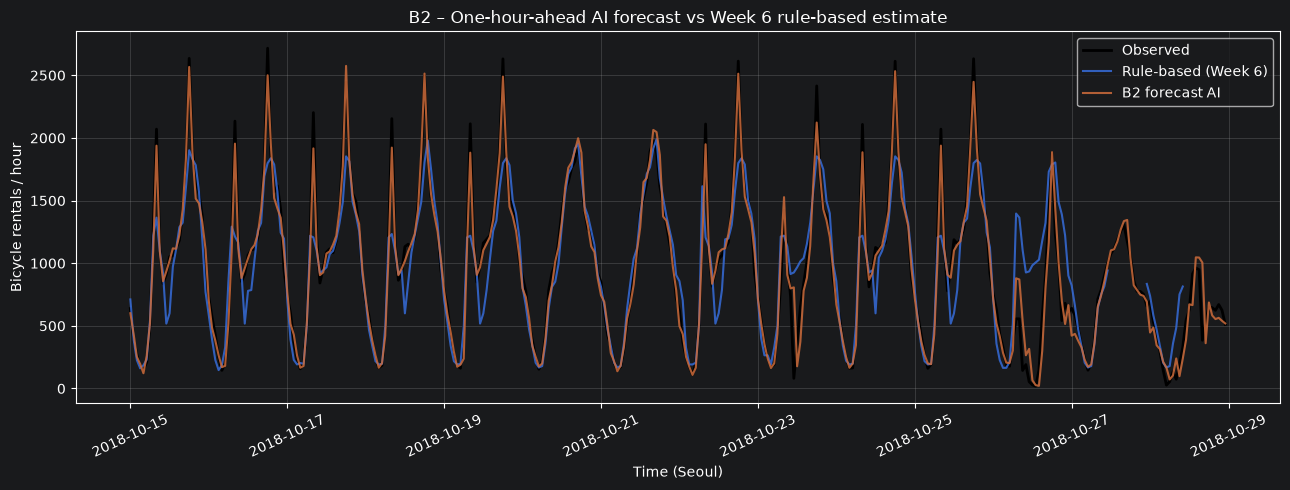

In [11]:
plot_test(['Rule-based (Week 6)', 'B2 forecast AI'], 'B2 – One-hour-ahead AI forecast vs Week 6 rule-based estimate')

*Interpretation:* this is a **rolling one-hour-ahead backtest** — before every test hour the real rentals of the two previous hours are known. It is not a multi-day recursive forecast (see Section 11 for that).

## 8. B3 — Hybrid model: baseline + AI residual correction

`D_hybrid(t) = D_base(t) + r_AI(t)`, with `D_base` = the Week 5 calibrated linear model.

1. Split the training period in time: the first 70% (**part A**) and the last 30% (**part B**).
2. Calibrate the Week 5 baseline on part A only.
3. Compute its residuals on part B: `r(t) = D_observed(t) − D_base(t)`. These are **out-of-sample** errors, like the errors the baseline will make on the test period. (Residuals on the same data used for fitting would be too small and too optimistic.)
4. Train a Random Forest to predict `r(t)` from information available at prediction time.
5. On the test period: `D_hybrid = D_base + r_AI`.

**Fair comparison (fix):** the residual model is trained on the errors of the *part-A* baseline (`b_base`), so the effect of the AI correction is measured as **`Hybrid baseline only` vs `B3 hybrid`** (same baseline, same hours). `Week 5 linear` (fitted on the whole pre-test period) remains a separate benchmark; its difference to the hybrid is not only due to the correction.

**Residual definition:** residuals are computed against the **unclipped** baseline `X·b_base`, and on the test period the correction is added to the same unclipped baseline; only the final hybrid value is clipped at 0. `Hybrid baseline only` is clipped at 0 for reporting, exactly like every other model.

In [12]:
cut = train['Timestamp'].iloc[int(len(train) * BASE_FIT_SHARE)]
part_a = train[train['Timestamp'] < cut]
part_b = train[train['Timestamp'] >= cut].copy()
assert part_a['Timestamp'].max() < part_b['Timestamp'].min() and part_b['Timestamp'].max() < TEST_START
print('Part A (baseline fit):', part_a.Timestamp.min(), '->', part_a.Timestamp.max(), f'({len(part_a)} h)')
print('Part B (residual fit):', part_b.Timestamp.min(), '->', part_b.Timestamp.max(), f'({len(part_b)} h)')

b_base, *_ = np.linalg.lstsq(week5_matrix(part_a), part_a['Observed'], rcond=None)
part_b['Residual'] = part_b['Observed'] - week5_matrix(part_b) @ b_base   # vs. UNCLIPPED baseline

B3_FEATURES_ORIGINAL = ['D_t', 'D_t1', 'T_next', 'H_next', 'Rain_next', 'Wind_next',
                        'Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month']
B3_FEATURES = B3_FEATURES_ORIGINAL + (['Cloud_next'] if USE_CLOUD_FEATURE else [])
assert 'Observed' not in B3_FEATURES
model_b3 = RandomForestRegressor(**RF_PARAMS).fit(part_b[B3_FEATURES], part_b['Residual'])

base_raw_test = week5_matrix(test) @ b_base                                 # same baseline definition
test['Hybrid baseline only'] = np.maximum(0, base_raw_test)
test['AI correction'] = model_b3.predict(test[B3_FEATURES])
test['B3 hybrid'] = np.maximum(0, base_raw_test + test['AI correction'])

print('B3 features:', B3_FEATURES)
print('Mean residual of the baseline on part B:', round(part_b['Residual'].mean(), 1))
print('Baseline only (part-A fit):', {k: round(v, 2) for k, v in scores(test['Observed'], test['Hybrid baseline only']).items()})
print('B3 hybrid:                 ', {k: round(v, 2) for k, v in scores(test['Observed'], test['B3 hybrid']).items()})
print('Week 5 linear (benchmark): ', {k: round(v, 2) for k, v in scores(test['Observed'], test['Week 5 linear']).items()})

Part A (baseline fit): 2017-12-01 02:00:00 -> 2018-07-06 17:00:00 (5172 h)
Part B (residual fit): 2018-07-06 18:00:00 -> 2018-10-14 23:00:00 (2217 h)
B3 features: ['D_t', 'D_t1', 'T_next', 'H_next', 'Rain_next', 'Wind_next', 'Hour', 'Weekday', 'Is weekend', 'Is holiday', 'Month', 'Cloud_next']
Mean residual of the baseline on part B: -32.8
Baseline only (part-A fit): {'MAE': 153.37, 'RMSE': 226.26, 'R²': 0.86}
B3 hybrid:                  {'MAE': 75.73, 'RMSE': 121.61, 'R²': 0.96}
Week 5 linear (benchmark):  {'MAE': 147.44, 'RMSE': 217.42, 'R²': 0.87}


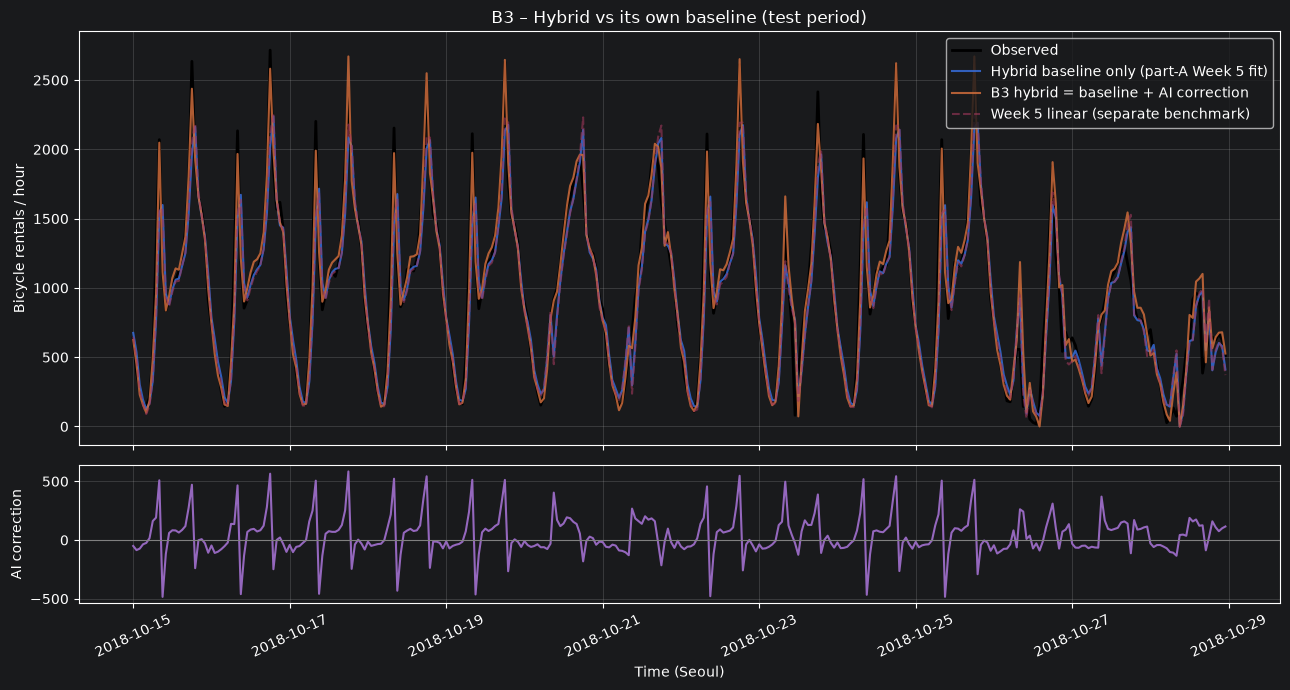

In [13]:
# Direct control pair: the hybrid's own baseline vs. the hybrid (+ the learned correction)
chart = test.set_index('Timestamp')[['Observed', 'Hybrid baseline only', 'B3 hybrid', 'Week 5 linear', 'AI correction']].asfreq('h')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(chart.index, chart['Observed'], label='Observed', color='black', linewidth=2)
ax1.plot(chart.index, chart['Hybrid baseline only'], label='Hybrid baseline only (part-A Week 5 fit)', alpha=0.85)
ax1.plot(chart.index, chart['B3 hybrid'], label='B3 hybrid = baseline + AI correction', alpha=0.85)
ax1.plot(chart.index, chart['Week 5 linear'], label='Week 5 linear (separate benchmark)', linestyle='--', alpha=0.6)
ax1.set_title('B3 – Hybrid vs its own baseline (test period)')
ax1.set_ylabel('Bicycle rentals / hour')
ax1.legend()
ax1.grid(alpha=0.3)
ax2.plot(chart.index, chart['AI correction'], color='tab:purple')
ax2.axhline(0, color='grey', linewidth=0.8)
ax2.set_ylabel('AI correction')
ax2.set_xlabel('Time (Seoul)')
ax2.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 9. Comparison of all models on the same test period

Two tables:

1. **All test hours** — every model except the rule-based method has a prediction for every hour; `Coverage %` shows how many test hours each model could estimate.
2. **Common hours** — only hours where the rule-based method found matches, so all methods are compared on exactly the same timestamps.

Plus a **cloud ablation**: B1/B2/B3 retrained with their original feature lists (no cloud cover), same test hours.

In [14]:
MODELS = ['Rule-based (Week 6)', 'Week 5 linear', 'B1 direct AI', 'B2 forecast AI',
          'Hybrid baseline only', 'B3 hybrid']

def comparison(rows):
    table = {}
    for m in MODELS:
        ok = rows[m].notna()
        table[m] = {'Hours': int(ok.sum()), 'Coverage %': 100 * ok.mean(),
                    **scores(rows.loc[ok, 'Observed'], rows.loc[ok, m])}
    return pd.DataFrame(table).T

full = comparison(test)
common = comparison(test[covered])
print('All test hours (rule-based only on covered hours):')
print(full.round(2).to_string())
print('\nCommon hours (all methods available):')
print(common.round(2).to_string())

full.to_csv(OUTPUT_DIR / 'historical_metrics_all_hours.csv')
common.to_csv(OUTPUT_DIR / 'historical_metrics_common_hours.csv')
test.to_csv(OUTPUT_DIR / 'historical_test_predictions.csv', index=False)

All test hours (rule-based only on covered hours):
                      Hours  Coverage %     MAE    RMSE    R²
Rule-based (Week 6)   312.0       92.86  186.21  304.37  0.75
Week 5 linear         336.0      100.00  147.44  217.42  0.87
B1 direct AI          336.0      100.00  134.72  208.61  0.88
B2 forecast AI        336.0      100.00   71.03  107.86  0.97
Hybrid baseline only  336.0      100.00  153.37  226.26  0.86
B3 hybrid             336.0      100.00   75.73  121.61  0.96

Common hours (all methods available):
                      Hours  Coverage %     MAE    RMSE    R²
Rule-based (Week 6)   312.0       100.0  186.21  304.37  0.75
Week 5 linear         312.0       100.0  148.18  218.44  0.87
B1 direct AI          312.0       100.0  132.58  207.33  0.89
B2 forecast AI        312.0       100.0   69.61  103.28  0.97
Hybrid baseline only  312.0       100.0  155.63  229.16  0.86
B3 hybrid             312.0       100.0   71.83  113.96  0.97


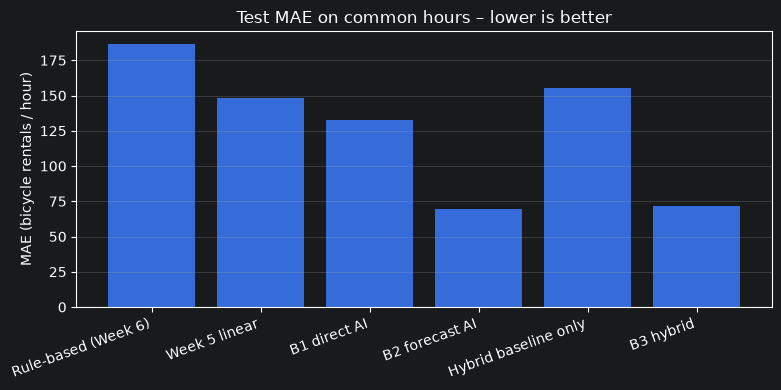

In [15]:
plt.figure(figsize=(8, 4))
plt.bar(common.index, common['MAE'])
plt.ylabel('MAE (bicycle rentals / hour)')
plt.title('Test MAE on common hours – lower is better')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Cloud ablation: same models, original feature lists (no cloud cover)
ablation = {}
if USE_CLOUD_FEATURE:
    for name, feats, rows, target in [('B1 direct AI', B1_FEATURES_ORIGINAL, train, 'Observed'),
                                      ('B2 forecast AI', B2_FEATURES_ORIGINAL, train, 'Observed'),
                                      ('B3 hybrid', B3_FEATURES_ORIGINAL, part_b, 'Residual')]:
        pred = RandomForestRegressor(**RF_PARAMS).fit(rows[feats], rows[target]).predict(test[feats])
        pred = np.maximum(0, base_raw_test + pred if name == 'B3 hybrid' else pred)
        ablation[name] = {'MAE with cloud': mae(test['Observed'], test[name]),
                          'MAE without cloud': mae(test['Observed'], pred),
                          'RMSE with cloud': rmse(test['Observed'], test[name]),
                          'RMSE without cloud': rmse(test['Observed'], pred)}
    ablation = pd.DataFrame(ablation).T
    print('Effect of the Open-Meteo cloud cover (all test hours, lower is better):')
    print(ablation.round(2).to_string())
    ablation.to_csv(OUTPUT_DIR / 'cloud_ablation.csv')

Effect of the Open-Meteo cloud cover (all test hours, lower is better):
                MAE with cloud  MAE without cloud  RMSE with cloud  RMSE without cloud
B1 direct AI            134.72             133.82           208.61              205.31
B2 forecast AI           71.03              70.38           107.86              107.76
B3 hybrid                75.73              74.01           121.61              119.53


## 10. Discussion

In [17]:
# All numbers below are computed from THIS run (no stored values)
def pct(new, old):
    return 100 * (old - new) / old

print(f"Cloud source used: {CLOUD_SOURCE}")
print(f"Test hours: {len(test)} | rule-based coverage: {covered.sum()} / {len(test)}\n")

b1, w5 = full.loc['B1 direct AI', 'MAE'], full.loc['Week 5 linear', 'MAE']
print(f"B1 vs Week 5 (all hours): MAE {b1:.1f} vs {w5:.1f} -> B1 is "
      f"{'better' if b1 < w5 else 'worse'} by {abs(pct(b1, w5)):.1f}%")

b2, rb = common.loc['B2 forecast AI', 'MAE'], common.loc['Rule-based (Week 6)', 'MAE']
print(f"B2 vs Week 6 rule-based (common hours): MAE {b2:.1f} vs {rb:.1f} -> B2 is "
      f"{'better' if b2 < rb else 'worse'} by {abs(pct(b2, rb)):.1f}%")

hb, b3 = full.loc['Hybrid baseline only', 'MAE'], full.loc['B3 hybrid', 'MAE']
print(f"B3 correction (same part-A baseline, all hours): MAE {hb:.1f} -> {b3:.1f} "
      f"({pct(b3, hb):+.1f}% error reduction)")

# When does the correction help? Error by day type and peak / off-peak hours
err = test.assign(
    Period=np.where(test['Hour'].isin([7, 8, 9, 17, 18, 19, 20]), 'peak (7–9, 17–20)', 'off-peak'),
    base_err=(test['Observed'] - test['Hybrid baseline only']).abs(),
    hybrid_err=(test['Observed'] - test['B3 hybrid']).abs())
breakdown = err.groupby(['Day type', 'Period'])[['base_err', 'hybrid_err']].mean()
breakdown['reduction %'] = pct(breakdown['hybrid_err'], breakdown['base_err'])
breakdown['hours'] = err.groupby(['Day type', 'Period']).size()
print('\nB3 – MAE of the baseline vs hybrid by situation:')
print(breakdown.rename(columns={'base_err': 'baseline MAE', 'hybrid_err': 'hybrid MAE'}).round(1).to_string())
helped = (err['hybrid_err'] < err['base_err']).mean() * 100
print(f"\nThe correction reduced the error in {helped:.0f}% of the test hours.")

Cloud source used: API: Open-Meteo Historical (ERA5), timezone=Asia/Seoul
Test hours: 336 | rule-based coverage: 312 / 336

B1 vs Week 5 (all hours): MAE 134.7 vs 147.4 -> B1 is better by 8.6%
B2 vs Week 6 rule-based (common hours): MAE 69.6 vs 186.2 -> B2 is better by 62.6%
B3 correction (same part-A baseline, all hours): MAE 153.4 -> 75.7 (+50.6% error reduction)

B3 – MAE of the baseline vs hybrid by situation:
                            baseline MAE  hybrid MAE  reduction %  hours
Day type Period                                                         
weekday  off-peak                   84.1        57.2         32.0    170
         peak (7–9, 17–20)         363.1       115.5         68.2     70
weekend  off-peak                   99.3        67.0         32.6     68
         peak (7–9, 17–20)         181.0       110.1         39.1     28

The correction reduced the error in 70% of the test hours.


**How to read the results** (the numbers are in the printed output above and change with every rerun of the data source/features):

- **B1 – Does AI learn demand patterns better?** Compare `B1 direct AI` with `Week 5 linear`. B1 sees **no past rentals**, only weather + calendar, so it describes typical demand under given conditions. A Random Forest can learn non-linear interactions (e.g. the weekday morning peak that is missing on weekends) which the linear model with a fixed hour effect cannot.
- **B2 – One-hour-ahead forecast.** Compare `B2 forecast AI` with `Rule-based (Week 6)` on the **common hours**. B2 uses only information available at forecast time (`D(t)`, `D(t−1)`, current weather and cloud cover, known calendar). Its advantage comes mainly from the recent rental level.
- **B3 – Does the AI correction help?** The fair test is `Hybrid baseline only` vs `B3 hybrid` (same part-A baseline, same hours). The breakdown table shows in which situations (day type, peak/off-peak) the correction reduces the error. The hybrid keeps the interpretable Week 5 equation and adds a learned correction.
- **Cloud cover (Week 6 integration).** The ablation table shows whether the Open-Meteo cloud cover changes the error of B1/B2/B3. A small or even negative effect is a valid finding: much of its information is already contained in humidity, rainfall and the recent rentals.

**Limitations:**
- The test period is only two weeks in autumn; results may differ in other seasons.
- Target-hour weather and cloud cover are a **perfect-forecast assumption** for Week 5, B1 and B3. In real operation a weather forecast would add error. B2 does not use this assumption.
- Cloud cover is ERA5 reanalysis at a grid point, not a station measurement.
- Random Forest settings were fixed in advance and not tuned on the test period.
- Rentals are a proxy for demand; shutdown hours are excluded, and supply limits are not visible in city-level totals.
- AI predictions are estimates, not observations, and must not be used as ground truth.

## 11. Separate scenario: forecast for 26–30 November 2026 (not validated)

This section is **not** part of the B1–B3 evaluation. It applies the models trained above to the hourly weather forecast of the **Open-Meteo Forecast API** for 2026-11-26 00:00 – 2026-11-30 23:00 (Seoul local time).

**Important restrictions:**
- There are **no observed 2026 rentals**, so no MAE/RMSE is computed and nothing is labelled "Observed". The curves are *scenario forecasts*.
- Hours that are already in the past at run time are kept in the table (flagged `past_at_run_time`) but not plotted. Hours without forecast weather are flagged `missing_forecast`; no value is invented.
- **Demand seeds:** Week 5, B2 and B3 need past rentals. There is no real 2026 `D(t)`, so the two seed hours (2026-11-25 22:00 and 23:00) are taken from a **historical profile**: the median rentals of the same hour on operating, non-holiday days of the same day type in November 2018 (*historical-seed scenario*). After that the models run **recursively**: each model's own previous prediction becomes its next `D(t)` / `D(t−1)`. B1 needs no seed.
- **Weather mapping:** `temperature_2m` → `T` (°C), `relative_humidity_2m` → `H` (%), `precipitation` → `Rain` (mm; includes snow water equivalent — only an approximation of the dataset's `Rainfall(mm)`), `wind_speed_10m` requested in **m/s** → `Wind`, `cloud_cover` → `Cloud` (%). Forecast model data ≠ the station observations / ERA5 used in training.
- **Holidays:** no validated holiday API is used. Explicit assumption: 26–30 Nov 2026 contain no Korean public holiday (official 2026 calendar checked manually) → `Is holiday = 0`.
- **Distribution shift:** the models learned 2017–2018 demand; the network and usage in 2026 differ. `Month = 11` never appears in the training data (training ends 2018-10-14), so the tree models treat it like a neighbouring month. Recursive errors accumulate over the 5 days.

In [18]:
FUTURE_START = pd.Timestamp('2026-11-26 00:00')
FUTURE_END = pd.Timestamp('2026-11-30 23:00')
FUTURE_HOLIDAYS = []          # explicit assumption, see text above
MANUAL_SEEDS = None           # e.g. {'D_t1': 900.0, 'D_t': 600.0} to override the historical seeds

run_time = pd.Timestamp.now(tz=SEOUL_TZ).tz_localize(None)
params = {'latitude': LAT, 'longitude': LON, 'timezone': SEOUL_TZ, 'wind_speed_unit': 'ms',
          'hourly': 'temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,cloud_cover',
          'start_date': (FUTURE_START - pd.Timedelta(days=1)).strftime('%Y-%m-%d'),
          'end_date': FUTURE_END.strftime('%Y-%m-%d')}
response = requests.get(FORECAST_URL, params=params, timeout=60)
response.raise_for_status()   # no fallback: future weather is never invented
fc = response.json()
assert fc.get('utc_offset_seconds') == 9 * 3600, 'Forecast is not in Seoul local time'
expected_units = {'temperature_2m': '°C', 'relative_humidity_2m': '%', 'precipitation': 'mm',
                  'wind_speed_10m': 'm/s', 'cloud_cover': '%'}
assert all(fc['hourly_units'][k] == u for k, u in expected_units.items()), fc['hourly_units']
(OUTPUT_DIR / 'open_meteo_forecast_raw.json').write_text(json.dumps(fc), encoding='utf-8')

h = fc['hourly']
wx = pd.DataFrame({'Timestamp': pd.to_datetime(h['time']),
                   'T': pd.to_numeric(pd.Series(h['temperature_2m']), errors='coerce'),
                   'H': pd.to_numeric(pd.Series(h['relative_humidity_2m']), errors='coerce'),
                   'Rain': pd.to_numeric(pd.Series(h['precipitation']), errors='coerce'),
                   'Wind': pd.to_numeric(pd.Series(h['wind_speed_10m']), errors='coerce'),
                   'Cloud': pd.to_numeric(pd.Series(h['cloud_cover']), errors='coerce')})
assert not wx['Timestamp'].duplicated().any(), 'Duplicated forecast hours'
assert wx['H'].dropna().between(0, 100).all() and wx['Cloud'].dropna().between(0, 100).all()

# Full hourly grid incl. the two seed hours before the window; missing forecast hours stay NaN
grid = pd.DataFrame({'Timestamp': pd.date_range(FUTURE_START - pd.Timedelta(hours=2), FUTURE_END, freq='h')})
fut = grid.merge(wx, on='Timestamp', how='left', validate='one_to_one')
fut['Hour'] = fut['Timestamp'].dt.hour
fut['Weekday'] = fut['Timestamp'].dt.weekday
fut['Is weekend'] = (fut['Weekday'] >= 5).astype(int)
fut['Day type'] = np.where(fut['Weekday'] >= 5, 'weekend', 'weekday')
fut['Is holiday'] = fut['Timestamp'].dt.normalize().isin(pd.to_datetime(FUTURE_HOLIDAYS)).astype(int)
fut['Month'] = fut['Timestamp'].dt.month
weather_ok = fut[['T', 'H', 'Rain', 'Wind', 'Cloud']].notna().all(axis=1)

print('Forecast run time (Seoul):', run_time.floor('min'))
print('Forecast grid point:', fc['latitude'], fc['longitude'], '| hours returned:', len(wx))
print('Window hours:', int((fut.Timestamp >= FUTURE_START).sum()),
      '| with complete forecast weather:', int(weather_ok[fut.Timestamp >= FUTURE_START].sum()))

Forecast run time (Seoul): 2026-11-26 21:21:00
Forecast grid point: 37.55 126.9375 | hours returned: 144
Window hours: 120 | with complete forecast weather: 120


C:\Users\Házi Donát Zsolt\AppData\Local\Temp\ipykernel_35376\1188008107.py:34: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  fut['Weekday'] = fut['Timestamp'].dt.weekday


In [19]:
# Historical-seed scenario for the two hours before the window
def historical_seed(ts):
    ref = df[df['Operating'] & (df['Month'] == 11) & (df['Is holiday'] == 0)
             & (df['Hour'] == ts.hour) & (df['Day type'] == ('weekend' if ts.weekday() >= 5 else 'weekday'))]
    return float(ref['Rented Bike Count'].median()), len(ref)

seed_t1_time, seed_t_time = FUTURE_START - pd.Timedelta(hours=2), FUTURE_START - pd.Timedelta(hours=1)
if MANUAL_SEEDS:
    seeds = dict(MANUAL_SEEDS, source='manual')
else:
    (s1, n1), (s0, n0) = historical_seed(seed_t1_time), historical_seed(seed_t_time)
    seeds = {'D_t1': s1, 'D_t': s0,
             'source': f'historical-seed scenario: median Nov-2018 rentals, same hour & day type (n={n1}, {n0} days)'}
print(f"Seeds: D({seed_t1_time}) = {seeds['D_t1']:.0f}, D({seed_t_time}) = {seeds['D_t']:.0f} | {seeds['source']}")

def feature_row(i, d_t, d_t1):
    # Features for target hour fut.iloc[i]; '*_now' = forecast weather of the previous hour
    now, nxt = fut.iloc[i - 1], fut.iloc[i]
    return pd.DataFrame([{
        'D_t': d_t, 'D_t1': d_t1,
        'T_now': now['T'], 'H_now': now['H'], 'Rain_now': now['Rain'], 'Wind_now': now['Wind'], 'Cloud_now': now['Cloud'],
        'T_next': nxt['T'], 'H_next': nxt['H'], 'Rain_next': nxt['Rain'], 'Wind_next': nxt['Wind'], 'Cloud_next': nxt['Cloud'],
        'Hour': nxt['Hour'], 'Weekday': nxt['Weekday'], 'Is weekend': nxt['Is weekend'],
        'Is holiday': nxt['Is holiday'], 'Month': nxt['Month']}])

# Recursive paths: every model continues from ITS OWN previous predictions (no 2026 observations exist)
paths = {name: [seeds['D_t1'], seeds['D_t']] for name in ['Week 5', 'B2', 'B3']}
records = []
for i in range(2, len(fut)):
    rec = {'Timestamp': fut['Timestamp'].iloc[i]}
    if weather_ok.iloc[i] and weather_ok.iloc[i - 1] and not np.isnan(paths['B3'][-1]):
        x_w5, x_b2, x_b3 = (feature_row(i, paths[m][-1], paths[m][-2]) for m in ['Week 5', 'B2', 'B3'])
        rec['Week 5 baseline (recursive)'] = max(0.0, float((week5_matrix(x_w5) @ b_week5)[0]))
        rec['B1 direct AI'] = max(0.0, float(model_b1.predict(x_w5[B1_FEATURES])[0]))
        rec['B2 recursive AI'] = max(0.0, float(model_b2.predict(x_b2[B2_FEATURES])[0]))
        b3_base = float((week5_matrix(x_b3) @ b_base)[0])           # same unclipped part-A baseline as in training
        rec['B3 baseline term'] = max(0.0, b3_base)
        rec['AI correction'] = float(model_b3.predict(x_b3[B3_FEATURES])[0])
        rec['B3 hybrid (recursive)'] = max(0.0, b3_base + rec['AI correction'])
        paths['Week 5'].append(rec['Week 5 baseline (recursive)'])
        paths['B2'].append(rec['B2 recursive AI'])
        paths['B3'].append(rec['B3 hybrid (recursive)'])
    else:
        # Missing forecast weather: stop the recursion, do not invent values
        for m in paths:
            paths[m].append(np.nan)
    records.append(rec)

future = fut.iloc[2:].reset_index(drop=True).merge(pd.DataFrame(records), on='Timestamp', validate='one_to_one')
future['Status'] = np.select(
    [~weather_ok.iloc[2:].to_numpy(), future['Timestamp'] <= run_time],
    ['missing_forecast', 'past_at_run_time'], default='future')
assert 'Observed' not in future.columns and 'Rented Bike Count' not in future.columns
assert future['Timestamp'].min() == FUTURE_START and future['Timestamp'].max() == FUTURE_END

FUTURE_MODELS = ['Week 5 baseline (recursive)', 'B1 direct AI', 'B2 recursive AI', 'B3 hybrid (recursive)']
print(future['Status'].value_counts().to_string())
print('\nFirst future hours (scenario forecast, rentals / hour):')
print(future.loc[future.Status == 'future', ['Timestamp', 'T', 'Cloud'] + FUTURE_MODELS].head(8).round(1).to_string(index=False))

Seeds: D(2026-11-25 22:00:00) = 902, D(2026-11-25 23:00:00) = 611 | historical-seed scenario: median Nov-2018 rentals, same hour & day type (n=20, 20 days)
Status
future              98
past_at_run_time    22

First future hours (scenario forecast, rentals / hour):
          Timestamp   T  Cloud  Week 5 baseline (recursive)  B1 direct AI  B2 recursive AI  B3 hybrid (recursive)
2026-11-26 22:00:00 9.3      0                        650.8         706.3            809.4                 1112.1
2026-11-26 23:00:00 8.8      0                        388.4         428.9            707.6                  783.0
2026-11-27 00:00:00 8.6      1                        249.1         320.9            501.1                  601.5
2026-11-27 01:00:00 8.6      9                        130.3         284.9            409.9                  421.7
2026-11-27 02:00:00 8.3      5                          4.2         261.8            271.1                  247.7
2026-11-27 03:00:00 8.3      5                    

C:\Users\Házi Donát Zsolt\AppData\Local\Temp\ipykernel_35376\1843237592.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(future.loc[future.Status == 'future', ['Timestamp', 'T', 'Cloud'] + FUTURE_MODELS].head(8).round(1).to_string(index=False))


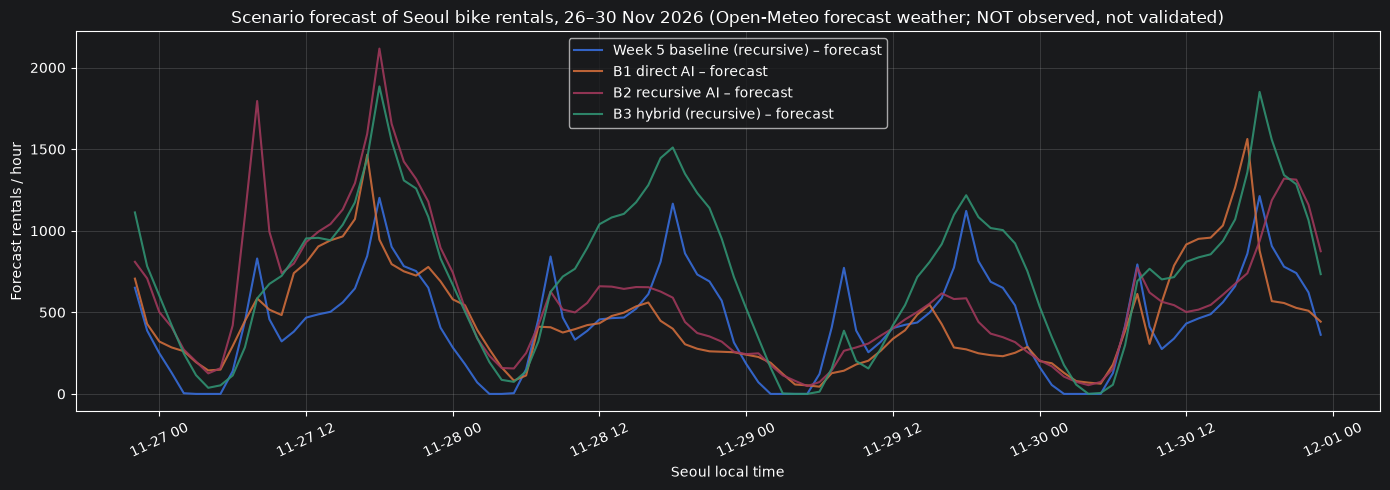

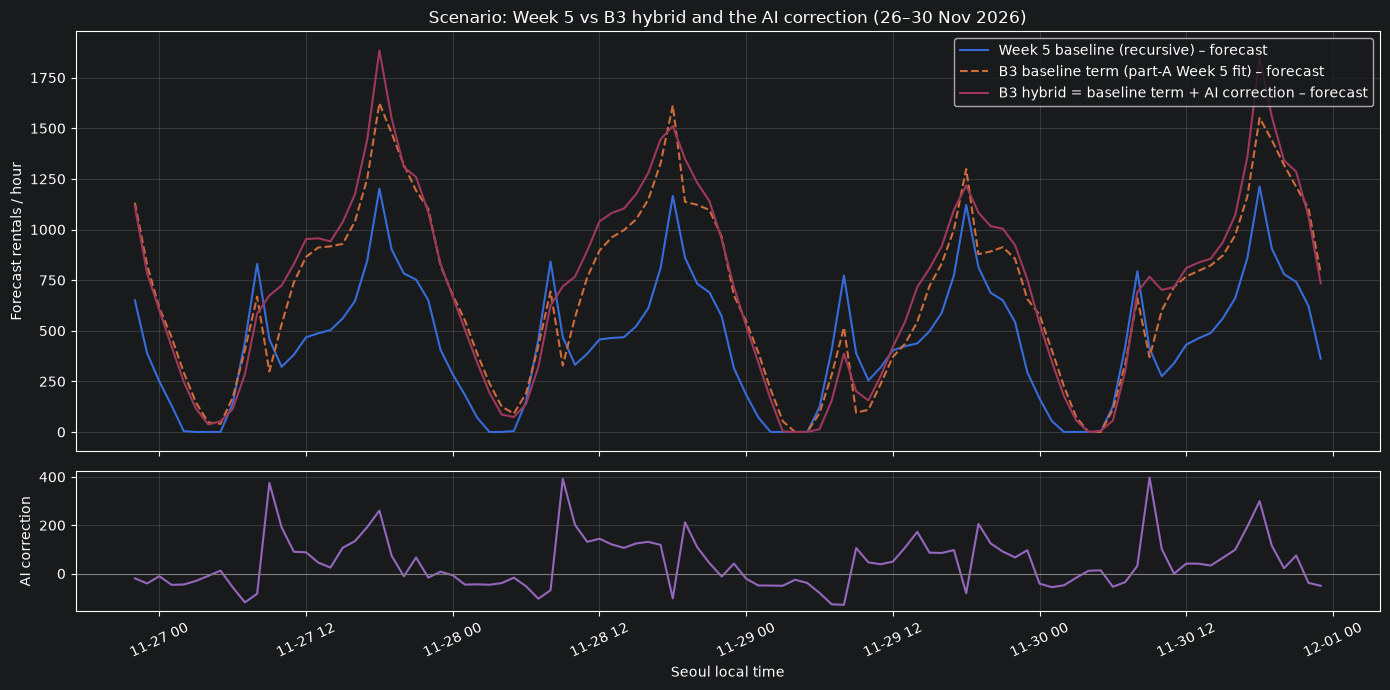

{
  "run_time_seoul": "2026-11-26 21:21:47.213300",
  "window": [
    "2026-11-26 00:00:00",
    "2026-11-30 23:00:00"
  ],
  "forecast_source": "Open-Meteo Forecast API (https://api.open-meteo.com/v1/forecast), timezone=Asia/Seoul, wind in m/s",
  "forecast_grid_point": [
    37.55,
    126.9375
  ],
  "historical_cloud_source": "API: Open-Meteo Historical (ERA5), timezone=Asia/Seoul",
  "seeds": {
    "2026-11-25 22:00:00": 902.0,
    "2026-11-25 23:00:00": 611.0,
    "source": "historical-seed scenario: median Nov-2018 rentals, same hour & day type (n=20, 20 days)"
  },
  "status_counts": {
    "future": 98,
    "past_at_run_time": 22
  },
  "holiday_assumption": "No Korean public holiday 26–30 Nov 2026 (manual, not API-validated)",
  "note": "Scenario forecast only. No observed 2026 rentals -> no error metrics."
}


In [20]:
# Only real future hours with forecast weather are plotted
show = future.set_index('Timestamp')
show.loc[show['Status'] != 'future', FUTURE_MODELS + ['B3 baseline term', 'AI correction']] = np.nan

fig, ax = plt.subplots(figsize=(14, 5))
for m in FUTURE_MODELS:
    ax.plot(show.index, show[m], label=m + ' – forecast', alpha=0.9)
ax.set_title('Scenario forecast of Seoul bike rentals, 26–30 Nov 2026 (Open-Meteo forecast weather; NOT observed, not validated)')
ax.set_xlabel('Seoul local time')
ax.set_ylabel('Forecast rentals / hour')
ax.grid(alpha=0.3)
ax.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'future_scenario_2026_11_26_30.png', dpi=150)
plt.show()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(show.index, show['Week 5 baseline (recursive)'], label='Week 5 baseline (recursive) – forecast')
ax1.plot(show.index, show['B3 baseline term'], label='B3 baseline term (part-A Week 5 fit) – forecast', linestyle='--')
ax1.plot(show.index, show['B3 hybrid (recursive)'], label='B3 hybrid = baseline term + AI correction – forecast')
ax1.set_title('Scenario: Week 5 vs B3 hybrid and the AI correction (26–30 Nov 2026)')
ax1.set_ylabel('Forecast rentals / hour')
ax1.legend()
ax1.grid(alpha=0.3)
ax2.plot(show.index, show['AI correction'], color='tab:purple')
ax2.axhline(0, color='grey', linewidth=0.8)
ax2.set_ylabel('AI correction')
ax2.set_xlabel('Seoul local time')
ax2.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'future_week5_vs_b3_correction.png', dpi=150)
plt.show()

future.to_csv(OUTPUT_DIR / 'future_scenario_2026_11_26_30.csv', index=False)
metadata = {
    'run_time_seoul': str(run_time), 'window': [str(FUTURE_START), str(FUTURE_END)],
    'forecast_source': f'Open-Meteo Forecast API ({FORECAST_URL}), timezone=Asia/Seoul, wind in m/s',
    'forecast_grid_point': [fc['latitude'], fc['longitude']],
    'historical_cloud_source': CLOUD_SOURCE,
    'seeds': {str(seed_t1_time): seeds['D_t1'], str(seed_t_time): seeds['D_t'], 'source': seeds['source']},
    'status_counts': future['Status'].value_counts().to_dict(),
    'holiday_assumption': 'No Korean public holiday 26–30 Nov 2026 (manual, not API-validated)',
    'note': 'Scenario forecast only. No observed 2026 rentals -> no error metrics.',
}
(OUTPUT_DIR / 'future_scenario_metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(metadata, indent=2, ensure_ascii=False))